# Bernstein-Vazirani Algorithm

A hidden n-bit **secret string s** defines the function f(x) = s·x mod 2
(the parity of the bits of x where s has a 1).
Classically, finding s needs **n** calls to f: query x = 00…01, 00…10, … to read one bit of s each time.
The Bernstein-Vazirani algorithm finds the whole of s with **one** call to the oracle
U<sub>f</sub>|x⟩|y⟩ = |x⟩|y ⊕ f(x)⟩.

Steps: prepare |0…0⟩|1⟩ → H on all qubits → oracle → H on the n input qubits → measure them.
The oracle has one CNOT for each 1 in s, and the measurement gives s directly.

The circuit is the same as Deutsch-Jozsa with a balanced oracle; here the goal is to *find* s,
not just to say constant or balanced.

**Input:** the secret string s (e.g. `1011`). n is its length.
**Expected:** the measured string equals s in all shots (`Correct: True`).
The second cell saves the circuit diagram as a PNG.

Enter the secret bit string s (e.g. 1011): 1011


Number of input qubits n = 4

Counts: {'1011': 1024}
Secret string s: 1011
Measured string: 1011
Correct: True
Oracle calls: quantum = 1, classical = 4


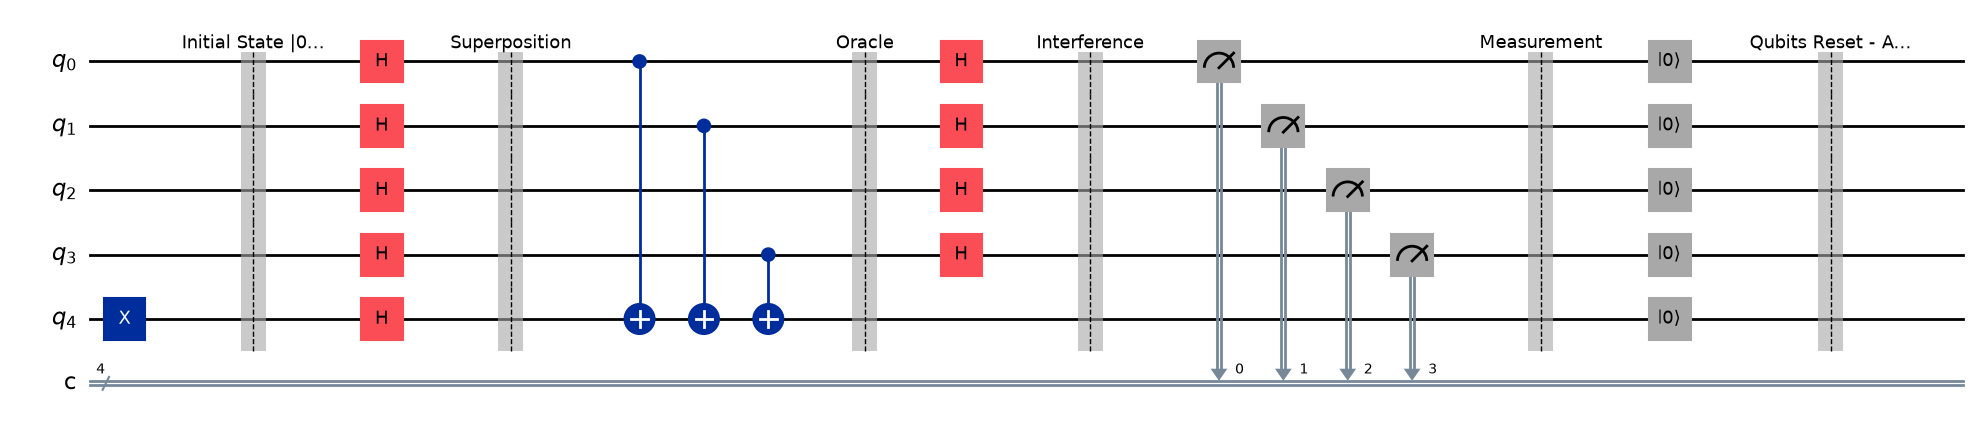

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator

# Input secret string
s = input("Enter the secret bit string s (e.g. 1011): ").strip()

if s == "" or set(s) - {"0", "1"}:
    raise ValueError("Enter a string of 0s and 1s.")

n = len(s)
print("Number of input qubits n =", n)

# Registers: q[0]..q[n-1] = input x, q[n] = output y
q = QuantumRegister(n + 1, 'q')
c = ClassicalRegister(n, 'c')

qc = QuantumCircuit(q, c)

# Prepare |0...0>|1>
qc.x(q[n])
qc.barrier(label="Initial State |0...0>|1>")

# Superposition
for i in range(n + 1):
    qc.h(q[i])
qc.barrier(label="Superposition")

# Oracle: f(x) = s.x mod 2, one CNOT for each 1 in s
# s is written q[n-1]...q[0], like Qiskit results
for i in range(n):
    if s[n - 1 - i] == "1":
        qc.cx(q[i], q[n])
qc.barrier(label="Oracle")

# Interference
for i in range(n):
    qc.h(q[i])
qc.barrier(label="Interference")

# Measurement
for i in range(n):
    qc.measure(q[i], c[i])
qc.barrier(label="Measurement")

# Reset all qubits after measurement
for i in range(n + 1):
    qc.reset(q[i])
qc.barrier(label="Qubits Reset - Available for Reuse")

# Run circuit
result = AerSimulator().run(qc, shots=1024).result()
counts = result.get_counts()
print("\nCounts:", counts)

found = max(counts, key=counts.get)

print("Secret string s:", s)
print("Measured string:", found)
print("Correct:", found == s)
print("Oracle calls: quantum = 1, classical =", n)

# Draw circuit
qc.draw(output='mpl', fold=-1, scale=1.0)

In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("5_BernsteinVazirani.png", dpi=300, bbox_inches="tight")